# Regression analysis of student exam outcomes

This notebook fits and evaluates three models on `data/data2`: a simple linear regression, a multiple linear regression, and a logistic regression. Each model uses a reproducible 80/20 train/test split. The test set is held out from model fitting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data_path = Path("data") / "data2"
if not data_path.exists():
    raise FileNotFoundError(f"Could not find the dataset at {data_path.resolve()}")

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print(f"Missing values: {int(df.isna().sum().sum())}")
display(df.head())
display(df[["exam_score", "passed"]].describe())

Dataset shape: (5000, 10)
Missing values: 0


,student_id,age,study_hours_per_week,attendance_percentage,previous_exam_score,sleep_hours_per_night,internet_access,part_time_job,exam_score,passed
0,STU00001,22,10.1,80.5,53.7,7.5,No,No,91.9,0
1,STU00002,55,9.7,93.0,67.4,7.9,Yes,No,100.0,0
2,STU00003,49,15.8,91.6,68.4,6.8,Yes,No,100.0,0
3,STU00004,39,16.1,78.1,45.9,6.9,Yes,No,99.4,0
4,STU00005,38,9.3,50.0,51.9,6.4,Yes,No,62.0,0


,exam_score,passed
count,5000.000000,5000.00000
mean,91.291120,0.37300
std,9.282893,0.48365
min,53.700000,0.00000
25%,85.600000,0.00000
50%,93.800000,0.00000
75%,100.000000,1.00000
max,100.000000,1.00000


## 1. Simple linear regression

Use weekly study hours as the single predictor of exam score. Report test-set mean squared error (MSE), R², mean absolute error (MAE), and root mean squared error (RMSE). The fitted slope describes the estimated change in exam score for one additional weekly study hour. The diagnostic plots show the first 10 held-out test observations.

Intercept: 79.446
Slope (per additional study hour/week): 0.977
Test MSE: 53.848
Test R²: 0.306
Test MAE: 5.926
Test RMSE: 7.338


,student_id,study_hours_per_week,actual_exam_score,predicted_exam_score,residual
1501,STU01502,2.1,72.9,81.498,-8.598
2586,STU02587,18.3,95.0,97.333,-2.333
2653,STU02654,6.9,84.4,86.190,-1.790
1055,STU01056,18.6,100.0,97.626,2.374
705,STU00706,7.5,79.2,86.776,-7.576
106,STU00107,9.8,100.0,89.025,10.975
589,STU00590,14.4,90.5,93.521,-3.021
2468,STU02469,18.0,100.0,97.039,2.961
2413,STU02414,10.9,84.7,90.100,-5.400
1600,STU01601,11.2,100.0,90.393,9.607


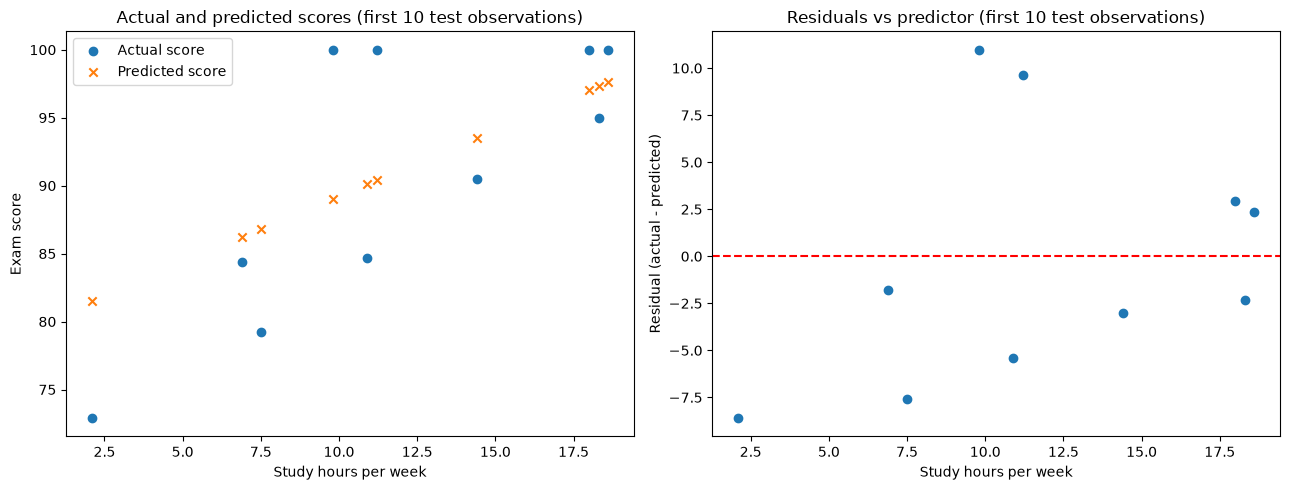

In [2]:
X_simple = df[["study_hours_per_week"]]
y_score = df["exam_score"]
X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple, y_score, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_simple_train)
simple_predictions = simple_model.predict(X_simple_test)

simple_mse = mean_squared_error(y_simple_test, simple_predictions)
simple_r2 = r2_score(y_simple_test, simple_predictions)
simple_residuals = y_simple_test - simple_predictions

print(f"Intercept: {simple_model.intercept_:.3f}")
print(f"Slope (per additional study hour/week): {simple_model.coef_[0]:.3f}")
print(f"Test MSE: {simple_mse:.3f}")
print(f"Test R²: {simple_r2:.3f}")
print(f"Test MAE: {mean_absolute_error(y_simple_test, simple_predictions):.3f}")
print(f"Test RMSE: {np.sqrt(simple_mse):.3f}")

diagnostic_data = pd.DataFrame(
    {
        "student_id": df.loc[y_simple_test.index, "student_id"],
        "study_hours_per_week": X_simple_test["study_hours_per_week"],
        "actual_exam_score": y_simple_test,
        "predicted_exam_score": simple_predictions,
        "residual": simple_residuals,
    }
)
first_10 = diagnostic_data.head(10)
display(first_10.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    first_10["study_hours_per_week"],
    first_10["actual_exam_score"],
    label="Actual score",
)
axes[0].scatter(
    first_10["study_hours_per_week"],
    first_10["predicted_exam_score"],
    marker="x",
    label="Predicted score",
)
axes[0].set_xlabel("Study hours per week")
axes[0].set_ylabel("Exam score")
axes[0].set_title("Actual and predicted scores (first 10 test observations)")
axes[0].legend()

axes[1].scatter(first_10["study_hours_per_week"], first_10["residual"])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Study hours per week")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predictor (first 10 test observations)")
fig.tight_layout()
plt.show()

## 2. Multiple linear regression

Predict exam score using age, study hours, attendance, previous exam score, sleep, internet access, and part-time job status. The student ID and `passed` label are excluded: the ID is only an identifier, while `passed` is a separate outcome. Categorical predictors are one-hot encoded. Report test-set MSE, R², MAE, and RMSE, and inspect actual-versus-predicted scores and residuals for the first 10 held-out observations.

Test MSE: 37.190
Test R²: 0.521
Test MAE: 4.839
Test RMSE: 6.098


,student_id,actual_exam_score,predicted_exam_score,residual
1501,STU01502,72.9,75.344,-2.444
2586,STU02587,95.0,93.214,1.786
2653,STU02654,84.4,87.212,-2.812
1055,STU01056,100.0,102.787,-2.787
705,STU00706,79.2,91.835,-12.635
106,STU00107,100.0,93.346,6.654
589,STU00590,90.5,96.020,-5.520
2468,STU02469,100.0,100.197,-0.197
2413,STU02414,84.7,90.687,-5.987
1600,STU01601,100.0,90.326,9.674


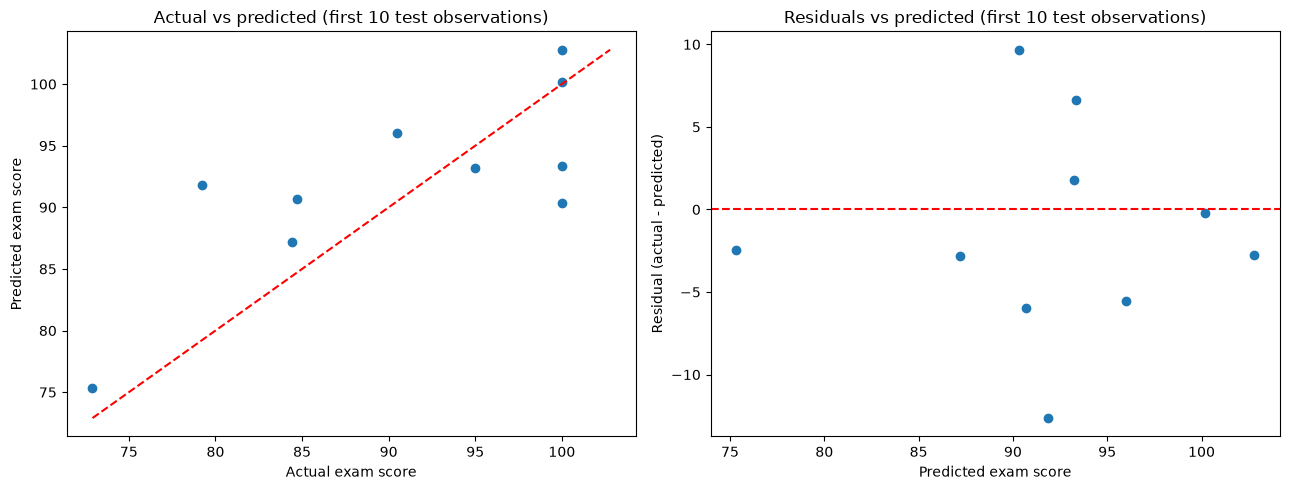

In [3]:
numeric_features = [
    "age",
    "study_hours_per_week",
    "attendance_percentage",
    "previous_exam_score",
    "sleep_hours_per_night",
]
categorical_features = ["internet_access", "part_time_job"]
score_features = numeric_features + categorical_features
X_multiple = df[score_features]
X_multiple_train, X_multiple_test, y_multiple_train, y_multiple_test = train_test_split(
    X_multiple, y_score, test_size=0.2, random_state=42
)

multiple_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    remainder="passthrough",
)
multiple_model = Pipeline(
    steps=[("preprocessor", multiple_preprocessor), ("regressor", LinearRegression())]
)
multiple_model.fit(X_multiple_train, y_multiple_train)
multiple_predictions = multiple_model.predict(X_multiple_test)
multiple_mse = mean_squared_error(y_multiple_test, multiple_predictions)
multiple_r2 = r2_score(y_multiple_test, multiple_predictions)
multiple_residuals = y_multiple_test - multiple_predictions

print(f"Test MSE: {multiple_mse:.3f}")
print(f"Test R²: {multiple_r2:.3f}")
print(f"Test MAE: {mean_absolute_error(y_multiple_test, multiple_predictions):.3f}")
print(f"Test RMSE: {np.sqrt(multiple_mse):.3f}")

multiple_diagnostic_data = pd.DataFrame(
    {
        "student_id": df.loc[y_multiple_test.index, "student_id"],
        "actual_exam_score": y_multiple_test,
        "predicted_exam_score": multiple_predictions,
        "residual": multiple_residuals,
    }
)
multiple_first_10 = multiple_diagnostic_data.head(10)
display(multiple_first_10.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    multiple_first_10["actual_exam_score"],
    multiple_first_10["predicted_exam_score"],
)
score_min = min(
    multiple_first_10["actual_exam_score"].min(),
    multiple_first_10["predicted_exam_score"].min(),
)
score_max = max(
    multiple_first_10["actual_exam_score"].max(),
    multiple_first_10["predicted_exam_score"].max(),
)
axes[0].plot([score_min, score_max], [score_min, score_max], color="red", linestyle="--")
axes[0].set_xlabel("Actual exam score")
axes[0].set_ylabel("Predicted exam score")
axes[0].set_title("Actual vs predicted (first 10 test observations)")

axes[1].scatter(
    multiple_first_10["predicted_exam_score"], multiple_first_10["residual"]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted exam score")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predicted (first 10 test observations)")
fig.tight_layout()
plt.show()

## 3. Logistic regression

Predict the binary `passed` outcome from the student characteristics and study habits, excluding both `passed` and `exam_score`. Excluding exam score avoids using a closely related outcome measure as an input when predicting pass/fail. Numeric features are standardized and categorical features are one-hot encoded. The report includes test-set accuracy, precision, recall, F1, ROC-AUC, and the confusion matrix.

In [4]:
X_logistic = df[score_features]
y_passed = df["passed"]
X_logistic_train, X_logistic_test, y_logistic_train, y_logistic_test = train_test_split(
    X_logistic, y_passed, test_size=0.2, random_state=42, stratify=y_passed
)

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
logistic_model = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]
)
logistic_model.fit(X_logistic_train, y_logistic_train)
logistic_predictions = logistic_model.predict(X_logistic_test)
logistic_probabilities = logistic_model.predict_proba(X_logistic_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_logistic_test, logistic_predictions):.3f}")
print(f"Test precision: {precision_score(y_logistic_test, logistic_predictions, zero_division=0):.3f}")
print(f"Test recall: {recall_score(y_logistic_test, logistic_predictions, zero_division=0):.3f}")
print(f"Test F1: {f1_score(y_logistic_test, logistic_predictions, zero_division=0):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_logistic_test, logistic_probabilities):.3f}")
print("Confusion matrix (rows = actual, columns = predicted; labels [0, 1]):")
print(confusion_matrix(y_logistic_test, logistic_predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(y_logistic_test, logistic_predictions, labels=[0, 1], zero_division=0))

Test accuracy: 0.688
Test precision: 0.627
Test recall: 0.405
Test F1: 0.492
Test ROC-AUC: 0.716
Confusion matrix (rows = actual, columns = predicted; labels [0, 1]):
[[537  90]
 [222 151]]

Classification report:
              precision    recall  f1-score   support

           0       0.71      0.86      0.77       627
           1       0.63      0.40      0.49       373

    accuracy                           0.69      1000
   macro avg       0.67      0.63      0.63      1000
weighted avg       0.68      0.69      0.67      1000

